# EN-3160 Image Processing and Machine Vision
## Assignment 03

* **Name:** Dharmakeerthi P.K.G.C.L.
* **Index Number:** 230140J

### GitHub Repository

The complete code and related files are available in the GitHub repository:

[View the GitHub Repository](https://github.com/ChamodLD/Image-Processing-and-Machine-Vision-Assignment_03)

---

## Question 1

In [19]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

Epoch 1/10, Loss: 1.8072
Epoch 2/10, Loss: 1.6792
Epoch 3/10, Loss: 1.6191
Epoch 4/10, Loss: 1.5727
Epoch 5/10, Loss: 1.5337
Epoch 6/10, Loss: 1.4994
Epoch 7/10, Loss: 1.4693
Epoch 8/10, Loss: 1.4417
Epoch 9/10, Loss: 1.4151
Epoch 10/10, Loss: 1.3908


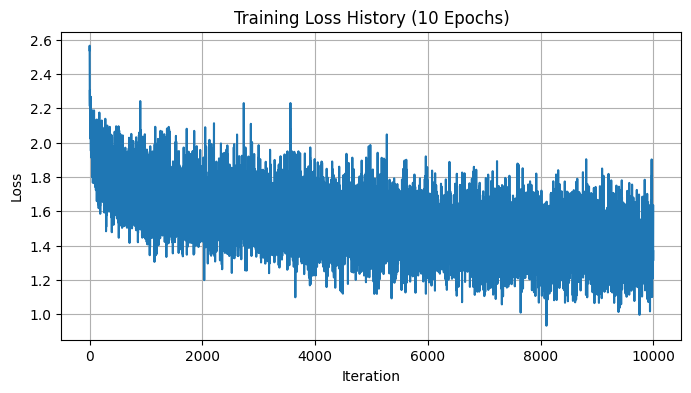

Training accuracy: 54.36%
Test accuracy: 47.85%


In [20]:

# 1. Dataloading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

batch_size = 50
trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (3072)
H = 100             # Middle/Hidden layer nodes (100 nodes)
K = 10              # Output size (number of classes)

# Initialize weights and biases (Xavier/Glorot Initialization)
std_1 = (2.0 / Din) ** 0.5
std_2 = (2.0 / H) ** 0.5

w1 = std_1 * torch.randn(Din, H)
b1 = torch.zeros(H)

w2 = std_2 * torch.randn(H, K)
b2 = torch.zeros(K)

# Hyperparameters
iterations = 10   # 10 epochs as required
lr = 1e-1        # Learning rate
lr_decay = 0.95
reg = 1e-4       # L2 Regularization factor
loss_history = []

# Helper function for Sigmoid
def sigmoid(x):
    return 1.0 / (1.0 + torch.exp(-x))

# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0] # Batch size
        x_train = inputs.view(Ntr, -1) # Flatten input to (Ntr, Din)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # --- Forward Pass ---
        z1 = x_train.mm(w1) + b1
        a1 = sigmoid(z1)
        y_pred = a1.mm(w2) + b2 # Raw logits
        
        # Softmax computation
        exp_scores = torch.exp(y_pred - torch.max(y_pred, dim=1, keepdim=True).values)
        probs = exp_scores / torch.sum(exp_scores, dim=1, keepdim=True)
        
        # --- Loss Calculation (Cross-Entropy with L2 Regularization) ---
        correct_logprobs = -torch.log(probs[range(Ntr), labels] + 1e-7)
        data_loss = torch.sum(correct_logprobs) / Ntr
        reg_loss = 0.5 * reg * (torch.sum(w1 * w1) + torch.sum(w2 * w2))
        loss = data_loss + reg_loss

        loss_history.append(loss.item())
        running_loss += loss.item()

        # --- Backpropagation ---
        dy_pred = (probs - y_train_onehot) / Ntr
        
        # Layer 2 Gradients
        dw2 = a1.t().mm(dy_pred) + reg * w2
        db2 = dy_pred.sum(dim=0)
        
        # Backprop into Layer 1
        da1 = dy_pred.mm(w2.t())
        dz1 = da1 * a1 * (1.0 - a1) # Sigmoid derivative
        
        # Layer 1 Gradients
        dw1 = x_train.t().mm(dz1) + reg * w1
        db1 = dz1.sum(dim=0)

        # --- Parameter Updates ---
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    print(f"Epoch {t+1}/{iterations}, Loss: {running_loss / len(trainloader):.4f}")
    lr *= lr_decay

# 4. Plotting the Loss History
plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.title("Training Loss History (10 Epochs)")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0

with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        
        a1 = sigmoid(x_train.mm(w1) + b1)
        y_train_pred = a1.mm(w2) + b2
        
        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0

with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)
        
        a1 = sigmoid(x_test.mm(w1) + b1)
        y_test_pred = a1.mm(w2) + b2
        
        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

In [21]:
# 2. Define Network Parameters & Architecture (1 Hidden Layer with 100 nodes)
Din = 3 * 32 * 32  # Input size (3072)
H = 100             # Hidden layer nodes
K = 10              # Output size (number of classes)

# Xavier/Glorot Initialization for weights and biases
std_1 = (2.0 / Din) ** 0.5
std_2 = (2.0 / H) ** 0.5

w1 = std_1 * torch.randn(Din, H)
b1 = torch.zeros(H)

w2 = std_2 * torch.randn(H, K)
b2 = torch.zeros(K)

# Hyperparameters
iterations = 10   # 10 epochs as required
lr = 1e-1        # Learning rate
lr_decay = 0.95
reg = 1e-4       # L2 Regularization factor
loss_history = []

# Helper function for Sigmoid activation
def sigmoid(x):
    return 1.0 / (1.0 + torch.exp(-x))

# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0] # Batch size
        x_train = inputs.view(Ntr, -1) # Flatten input to (Ntr, Din)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # --- Forward Pass ---
        z1 = x_train.mm(w1) + b1
        a1 = sigmoid(z1)
        y_pred = a1.mm(w2) + b2 # Raw logits
        
        # Softmax computation
        exp_scores = torch.exp(y_pred - torch.max(y_pred, dim=1, keepdim=True).values)
        probs = exp_scores / torch.sum(exp_scores, dim=1, keepdim=True)
        
        # --- Loss Calculation (Cross-Entropy with L2 Regularization) ---
        correct_logprobs = -torch.log(probs[range(Ntr), labels] + 1e-7)
        data_loss = torch.sum(correct_logprobs) / Ntr
        reg_loss = 0.5 * reg * (torch.sum(w1 * w1) + torch.sum(w2 * w2))
        loss = data_loss + reg_loss

        loss_history.append(loss.item())
        running_loss += loss.item()

        # --- Backpropagation ---
        dy_pred = (probs - y_train_onehot) / Ntr
        
        # Layer 2 Gradients
        dw2 = a1.t().mm(dy_pred) + reg * w2
        db2 = dy_pred.sum(dim=0)
        
        # Backprop into Layer 1
        da1 = dy_pred.mm(w2.t())
        dz1 = da1 * a1 * (1.0 - a1) # Sigmoid derivative
        
        # Layer 1 Gradients
        dw1 = x_train.t().mm(dz1) + reg * w1
        db1 = dz1.sum(dim=0)

        # --- Parameter Updates ---
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2

    print(f"Epoch {t+1}/{iterations}, Loss: {running_loss / len(trainloader):.4f}")
    lr *= lr_decay





Epoch 1/10, Loss: 1.8044
Epoch 2/10, Loss: 1.6765
Epoch 3/10, Loss: 1.6158
Epoch 4/10, Loss: 1.5694
Epoch 5/10, Loss: 1.5292
Epoch 6/10, Loss: 1.4953
Epoch 7/10, Loss: 1.4641
Epoch 8/10, Loss: 1.4368
Epoch 9/10, Loss: 1.4106
Epoch 10/10, Loss: 1.3875


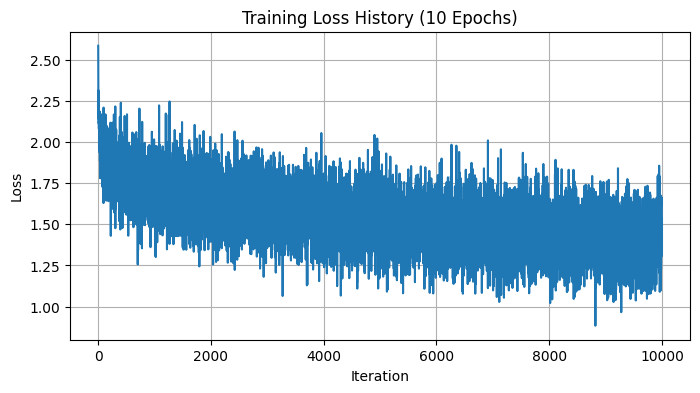

In [22]:
# 4. Plotting the Loss History
plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.title("Training Loss History (10 Epochs)")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.grid(True)
plt.show()


In [23]:
# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0

with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        
        a1 = sigmoid(x_train.mm(w1) + b1)
        y_train_pred = a1.mm(w2) + b2
        
        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()

train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")

Training accuracy: 54.34%


In [24]:

# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0

with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)
        
        a1 = sigmoid(x_test.mm(w1) + b1)
        y_test_pred = a1.mm(w2) + b2
        
        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()

test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")

Test accuracy: 48.32%


### Discussion
It can be observed that although the model's loss has been reduced with each epoch, the training and test accuracies are still low (Training acuracy = 54.34% , Test accuracy = 48.32%). This can be due to the model being too simple so that it underfits the dataset. Including more hidden layers can help achieve a greater accuracy.

## Question 2

- **Part a**

### Load dataset

In [25]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

batch_size = 64

trainset = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2)

testset = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)


### Model Architecture

In [26]:
class LeNet5(nn.Module):
    def __init__(self):
        super(LeNet5, self).__init__()
        self.conv1 = nn.Conv2d(1, 6, kernel_size=5, padding=2)
        self.pool = nn.AvgPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(6, 16, kernel_size=5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))
        x = x.view(-1, 16 * 5 * 5)
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x


### Training Loop

In [27]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
lenet_model = LeNet5().to(device)

criterion = nn.CrossEntropyLoss()
optimizer_lenet = optim.Adam(lenet_model.parameters(), lr=0.001)

# 3. Training Loop with Logging (10 Epochs)
epochs = 10
lenet_train_loss, lenet_train_acc = [], []
lenet_test_loss, lenet_test_acc = [], []

for epoch in range(epochs):
    lenet_model.train()
    running_loss, correct_train, total_train = 0.0, 0, 0
    
    for inputs, labels in trainloader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer_lenet.zero_grad()
        outputs = lenet_model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_lenet.step()
        
        running_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()
        
    epoch_train_loss = running_loss / total_train
    epoch_train_acc = 100 * correct_train / total_train
    lenet_train_loss.append(epoch_train_loss)
    lenet_train_acc.append(epoch_train_acc)
    
    # Evaluate Test per Epoch
    lenet_model.eval()
    test_loss, correct_test, total_test = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in testloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = lenet_model(inputs)
            loss = criterion(outputs, labels)
            test_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_test += labels.size(0)
            correct_test += (predicted == labels).sum().item()
            
    epoch_test_loss = test_loss / total_test
    epoch_test_acc = 100 * correct_test / total_test
    lenet_test_loss.append(epoch_test_loss)
    lenet_test_acc.append(epoch_test_acc)
    
    print(f"LeNet-5 Epoch {epoch+1}/{epochs} | Train Loss: {epoch_train_loss:.4f} Acc: {epoch_train_loss:.2f}% | Test Loss: {epoch_test_loss:.4f} Acc: {epoch_test_acc:.2f}%")

print(f"LeNet-5 Final Training Accuracy: {lenet_train_acc[-1]:.2f}%")
print(f"LeNet-5 Final Test Accuracy: {lenet_test_acc[-1]:.2f}%")

LeNet-5 Epoch 1/10 | Train Loss: 0.3013 Acc: 0.30% | Test Loss: 0.0988 Acc: 96.97%
LeNet-5 Epoch 2/10 | Train Loss: 0.0885 Acc: 0.09% | Test Loss: 0.0603 Acc: 98.05%
LeNet-5 Epoch 3/10 | Train Loss: 0.0612 Acc: 0.06% | Test Loss: 0.0546 Acc: 98.17%
LeNet-5 Epoch 4/10 | Train Loss: 0.0469 Acc: 0.05% | Test Loss: 0.0413 Acc: 98.67%
LeNet-5 Epoch 5/10 | Train Loss: 0.0388 Acc: 0.04% | Test Loss: 0.0362 Acc: 98.79%
LeNet-5 Epoch 6/10 | Train Loss: 0.0332 Acc: 0.03% | Test Loss: 0.0403 Acc: 98.73%
LeNet-5 Epoch 7/10 | Train Loss: 0.0287 Acc: 0.03% | Test Loss: 0.0370 Acc: 98.72%
LeNet-5 Epoch 8/10 | Train Loss: 0.0257 Acc: 0.03% | Test Loss: 0.0422 Acc: 98.74%
LeNet-5 Epoch 9/10 | Train Loss: 0.0209 Acc: 0.02% | Test Loss: 0.0314 Acc: 98.98%
LeNet-5 Epoch 10/10 | Train Loss: 0.0191 Acc: 0.02% | Test Loss: 0.0487 Acc: 98.41%
LeNet-5 Final Training Accuracy: 99.36%
LeNet-5 Final Test Accuracy: 98.41%


### Discusion
Both training and test accuracies are high (Training acuracy = 99.36% , Test accuracy = 98.41%), therefore model has well fit for the data.


- **Part b**

### CNN Architecture

In [28]:
class ModernCNN(nn.Module):
    def __init__(self):
        super(ModernCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.dropout = nn.Dropout2d(0.25)
        
        self.fc1 = nn.Linear(128 * 7 * 7, 256)
        self.fc2 = nn.Linear(256, 10)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.pool1(self.relu(self.bn1(self.conv1(x))))
        x = self.pool2(self.relu(self.bn2(self.conv2(x))))
        x = self.dropout(self.relu(self.bn3(self.conv3(x))))
        
        x = x.view(-1, 128 * 7 * 7)
        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x

### Training Loop

In [29]:
modern_model = ModernCNN().to(device)
optimizer_modern = optim.Adam(modern_model.parameters(), lr=0.001)

# 2. Training Loop with Logging (10 Epochs)
mod_train_loss, mod_train_acc = [], []
mod_test_loss, mod_test_acc = [], []

for epoch in range(epochs):
    modern_model.train()
    running_loss, correct_train, total_train = 0.0, 0, 0
    
    for inputs, labels in trainloader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer_modern.zero_grad()
        outputs = modern_model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_modern.step()
        
        running_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()
        
    epoch_train_loss = running_loss / total_train
    epoch_train_acc = 100 * correct_train / total_train
    mod_train_loss.append(epoch_train_loss)
    mod_train_acc.append(epoch_train_acc)
    
    # Evaluate Test per Epoch
    modern_model.eval()
    test_loss, correct_test, total_test = 0.0, 0, 0
    with torch.no_grad():
        for inputs, labels in testloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = modern_model(inputs)
            loss = criterion(outputs, labels)
            test_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_test += labels.size(0)
            correct_test += (predicted == labels).sum().item()
            
    epoch_test_loss = test_loss / total_test
    epoch_test_acc = 100 * correct_test / total_test
    mod_test_loss.append(epoch_test_loss)
    mod_test_acc.append(epoch_test_acc)
    
    print(f"Modern CNN Epoch {epoch+1}/{epochs} | Train Loss: {epoch_train_loss:.4f} Acc: {epoch_train_acc:.2f}% | Test Loss: {epoch_test_loss:.4f} Acc: {epoch_test_acc:.2f}%")

print(f"Modern CNN Final Training Accuracy: {mod_train_acc[-1]:.2f}%")
print(f"Modern CNN Final Test Accuracy: {mod_test_acc[-1]:.2f}%")

Modern CNN Epoch 1/10 | Train Loss: 0.1022 Acc: 96.78% | Test Loss: 0.0538 Acc: 98.26%
Modern CNN Epoch 2/10 | Train Loss: 0.0458 Acc: 98.56% | Test Loss: 0.0385 Acc: 98.79%
Modern CNN Epoch 3/10 | Train Loss: 0.0353 Acc: 98.93% | Test Loss: 0.0368 Acc: 98.90%
Modern CNN Epoch 4/10 | Train Loss: 0.0274 Acc: 99.11% | Test Loss: 0.0234 Acc: 99.24%
Modern CNN Epoch 5/10 | Train Loss: 0.0214 Acc: 99.34% | Test Loss: 0.0282 Acc: 99.15%
Modern CNN Epoch 6/10 | Train Loss: 0.0188 Acc: 99.36% | Test Loss: 0.0295 Acc: 99.13%
Modern CNN Epoch 7/10 | Train Loss: 0.0172 Acc: 99.49% | Test Loss: 0.0337 Acc: 99.03%
Modern CNN Epoch 8/10 | Train Loss: 0.0131 Acc: 99.58% | Test Loss: 0.0277 Acc: 99.26%
Modern CNN Epoch 9/10 | Train Loss: 0.0124 Acc: 99.62% | Test Loss: 0.0322 Acc: 99.17%
Modern CNN Epoch 10/10 | Train Loss: 0.0112 Acc: 99.61% | Test Loss: 0.0298 Acc: 99.27%
Modern CNN Final Training Accuracy: 99.61%
Modern CNN Final Test Accuracy: 99.27%


### Discusion
Both training and test accuracies are high (Training acuracy = 99.36% , Test accuracy = 98.41%), therefore model has well fit for the data.


- **Part c**

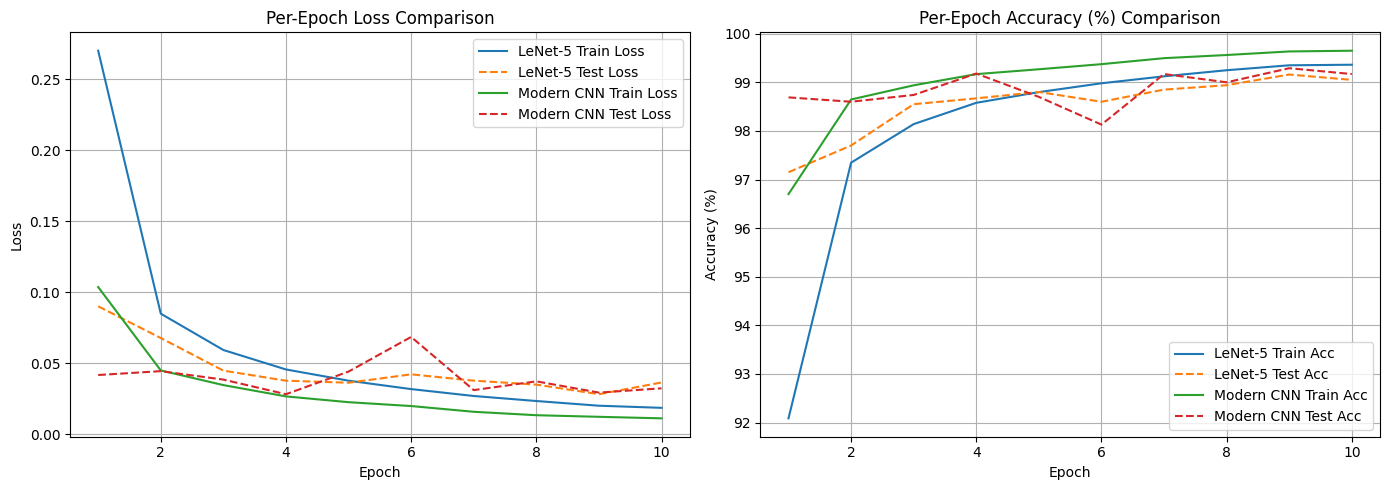

<Figure size 800x600 with 0 Axes>

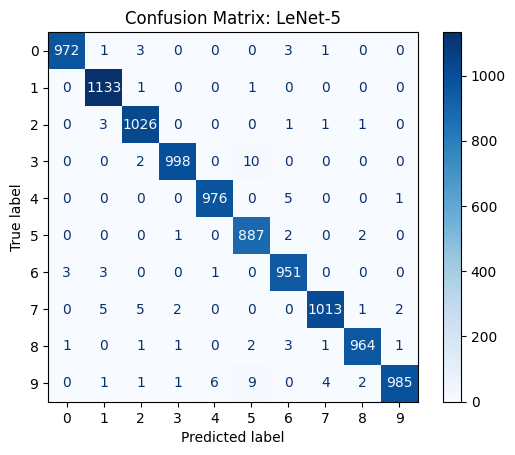

<Figure size 800x600 with 0 Axes>

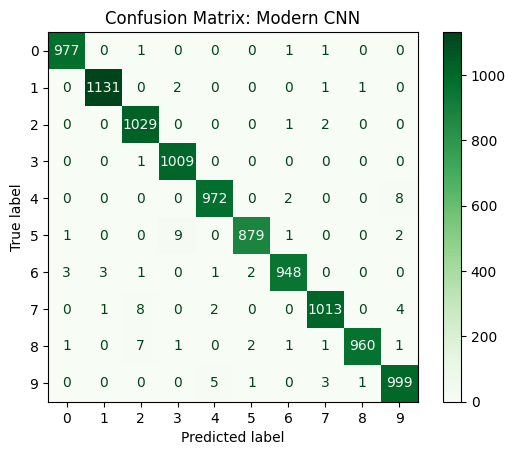

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np

# 1. Plotting Loss and Accuracy Curves
epochs_range = range(1, 11)

plt.figure(figsize=(14, 5))

# Loss Subplot
plt.subplot(1, 2, 1)
plt.plot(epochs_range, lenet_train_loss, label='LeNet-5 Train Loss')
plt.plot(epochs_range, lenet_test_loss, label='LeNet-5 Test Loss', linestyle='--')
plt.plot(epochs_range, mod_train_loss, label='Modern CNN Train Loss')
plt.plot(epochs_range, mod_test_loss, label='Modern CNN Test Loss', linestyle='--')
plt.title('Per-Epoch Loss Comparison')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Accuracy Subplot
plt.subplot(1, 2, 2)
plt.plot(epochs_range, lenet_train_acc, label='LeNet-5 Train Acc')
plt.plot(epochs_range, lenet_test_acc, label='LeNet-5 Test Acc', linestyle='--')
plt.plot(epochs_range, mod_train_acc, label='Modern CNN Train Acc')
plt.plot(epochs_range, mod_test_acc, label='Modern CNN Test Acc', linestyle='--')
plt.title('Per-Epoch Accuracy (%) Comparison')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# 2. Helper function to extract predictions and labels
def get_all_preds_and_labels(model, dataloader):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.numpy())
    return np.array(all_labels), np.array(all_preds)

y_true, lenet_preds = get_all_preds_and_labels(lenet_model, testloader)
cm_lenet = confusion_matrix(y_true, lenet_preds)

# LeNet-5 Confusion Matrix
plt.figure(figsize=(8, 6))
disp_lenet = ConfusionMatrixDisplay(confusion_matrix=cm_lenet, display_labels=range(10))
disp_lenet.plot(cmap=plt.cm.Blues, values_format='d')
plt.title("Confusion Matrix: LeNet-5")
plt.show()

_, mod_preds = get_all_preds_and_labels(modern_model, testloader)
cm_mod = confusion_matrix(y_true, mod_preds)

# Modern CNN Confusion Matrix
plt.figure(figsize=(8, 6))
disp_mod = ConfusionMatrixDisplay(confusion_matrix=cm_mod, display_labels=range(10))
disp_mod.plot(cmap=plt.cm.Greens, values_format='d')
plt.title("Confusion Matrix: Modern CNN")
plt.show()

### Discusion
The per-epoch loss curves indicate that the CNN achieves a lower training loss than the LeNet-5 model. Similarly, the CNN demonstrates higher training accuracy, suggesting that it learns the training data more effectively. However, the testing losses and testing accuracies of both models are approximately equal. This indicates that, despite the CNN's superior performance on the training dataset, it does not provide a significant improvement in generalization performance compared with LeNet-5. Therefore, both models exhibit similar performance on unseen data, while the CNN achieves better results during training.

## Question 3

In [ ]:
import urllib.request
import zipfile
import os

url = "https://download.pytorch.org/tutorial/hymenoptera_data.zip"
file_path = "hymenoptera_data.zip"

print("Downloading Hymenoptera dataset...")
urllib.request.urlretrieve(url, file_path)

print("Extracting dataset...")
with zipfile.ZipFile(file_path, 'r') as zip_ref:
    zip_ref.extractall('./')

# Clean up the zip file
os.remove(file_path)
print("Dataset downloaded and ready at './hymenoptera_data'!")

Extracting dataset...
Dataset downloaded and ready at './hymenoptera_data'!


### Data Augmentation and Normalization for Training

In [31]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
import torchvision
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
import time
import os
import copy


data_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

data_dir = './hymenoptera_data'
image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x), data_transforms[x]) for x in ['train', 'val']}
dataloaders = {x: torch.utils.data.DataLoader(image_datasets[x], batch_size=4, shuffle=True, num_workers=2) for x in ['train', 'val']}
dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val']}
class_names = image_datasets['train'].classes

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

### Function to train the model

In [32]:

def train_model(model, criterion, optimizer, scheduler, num_epochs=10):
    since = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    for epoch in range(num_epochs):
        print(f'Epoch {epoch}/{num_epochs - 1}')
        print('-' * 10)

        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0

            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            if phase == 'train':
                scheduler.step()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = float(running_corrects.double() / dataset_sizes[phase])

            print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())

        print()

    time_elapsed = time.time() - since
    print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Best Val Acc: {best_acc:4f}')

    model.load_state_dict(best_model_wts)
    return model

### (a) Fine-Tuning ResNet18

In [33]:
print("--- Training via Fine-Tuning ---")
model_ft = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
num_ftrs = model_ft.fc.in_features
# Replace the final fully connected layer for 2 classes (ants, bees)
model_ft.fc = nn.Linear(num_ftrs, 2)
model_ft = model_ft.to(device)

criterion = nn.CrossEntropyLoss()
optimizer_ft = optim.SGD(model_ft.parameters(), lr=0.001, momentum=0.9)
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_ft, step_size=7, gamma=0.1)

model_ft = train_model(model_ft, criterion, optimizer_ft, exp_lr_scheduler, num_epochs=10)


--- Training via Fine-Tuning ---
Epoch 0/9
----------
train Loss: 0.5659 Acc: 0.7131
val Loss: 0.5946 Acc: 0.7320

Epoch 1/9
----------
train Loss: 0.4427 Acc: 0.7828
val Loss: 0.1997 Acc: 0.9150

Epoch 2/9
----------
train Loss: 0.5214 Acc: 0.7664
val Loss: 0.3122 Acc: 0.8889

Epoch 3/9
----------
train Loss: 0.4503 Acc: 0.8197
val Loss: 0.2687 Acc: 0.9150

Epoch 4/9
----------
train Loss: 0.6640 Acc: 0.8197
val Loss: 1.2772 Acc: 0.6928

Epoch 5/9
----------
train Loss: 0.5970 Acc: 0.7869
val Loss: 0.3390 Acc: 0.8693

Epoch 6/9
----------
train Loss: 0.6767 Acc: 0.7623
val Loss: 0.5689 Acc: 0.8431

Epoch 7/9
----------
train Loss: 0.4997 Acc: 0.8484
val Loss: 0.2606 Acc: 0.9281

Epoch 8/9
----------
train Loss: 0.3878 Acc: 0.8648
val Loss: 0.2243 Acc: 0.9216

Epoch 9/9
----------
train Loss: 0.3356 Acc: 0.8770
val Loss: 0.2424 Acc: 0.9216

Training complete in 6m 4s
Best Val Acc: 0.928105


### (b) Feature Extraction Using ResNet18

In [34]:
print("\n--- Training via Feature Extraction ---")
model_conv = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Freeze all pre-trained convolutional parameters
for param in model_conv.parameters():
    param.requires_grad = False

# The newly created layers have requires_grad=True by default
num_ftrs = model_conv.fc.in_features
model_conv.fc = nn.Linear(num_ftrs, 2)
model_conv = model_conv.to(device)

criterion = nn.CrossEntropyLoss()
# Observe that only parameters of final layer are being optimized
optimizer_conv = optim.SGD(model_conv.fc.parameters(), lr=0.001, momentum=0.9)
exp_lr_scheduler_conv = lr_scheduler.StepLR(optimizer_conv, step_size=7, gamma=0.1)

model_conv = train_model(model_conv, criterion, optimizer_conv, exp_lr_scheduler_conv, num_epochs=10)


--- Training via Feature Extraction ---
Epoch 0/9
----------
train Loss: 0.5745 Acc: 0.6844
val Loss: 0.2631 Acc: 0.8954

Epoch 1/9
----------
train Loss: 0.5367 Acc: 0.7746
val Loss: 0.2458 Acc: 0.8758

Epoch 2/9
----------
train Loss: 0.6944 Acc: 0.7049
val Loss: 0.6626 Acc: 0.7059

Epoch 3/9
----------
train Loss: 0.5295 Acc: 0.7705
val Loss: 0.2207 Acc: 0.9281

Epoch 4/9
----------
train Loss: 0.4571 Acc: 0.8033
val Loss: 0.2832 Acc: 0.8824

Epoch 5/9
----------
train Loss: 0.4885 Acc: 0.7869
val Loss: 0.1992 Acc: 0.9281

Epoch 6/9
----------
train Loss: 0.5933 Acc: 0.7582
val Loss: 0.3513 Acc: 0.8824

Epoch 7/9
----------
train Loss: 0.3601 Acc: 0.8566
val Loss: 0.1987 Acc: 0.9346

Epoch 8/9
----------
train Loss: 0.3040 Acc: 0.8566
val Loss: 0.2029 Acc: 0.9281

Epoch 9/9
----------
train Loss: 0.4043 Acc: 0.8238
val Loss: 0.2416 Acc: 0.9085

Training complete in 4m 0s
Best Val Acc: 0.934641


## Discusion
The experimental results demonstrate that both fine-tuning and feature extraction using the pre-trained ResNet18 model achieved good classification performance on the Hymenoptera dataset. Fine-tuning achieved a best validation accuracy of 92.81%, whereas feature extraction achieved a slightly higher best validation accuracy of 93.46%. In addition, feature extraction required only 4 minutes to complete training, compared with 6 minutes and 4 seconds for fine-tuning.

Although fine-tuning achieved a lower final training loss and higher final training accuracy, the final validation accuracies of both approaches were relatively close, at 92.16% and 90.85%, respectively. Feature extraction also achieved a slightly lower final validation loss of 0.2416 compared with 0.2424 for fine-tuning. These results indicate that feature extraction provided competitive validation performance with reduced computational time, while fine-tuning enabled the model to fit the training data more closely.

Overall, feature extraction achieved the highest validation accuracy and was more computationally efficient in this experiment. However, the difference in the best validation accuracies was small. Therefore, both approaches are effective transfer learning strategies for the Hymenoptera classification task, and further evaluation on an independent test dataset would be required to determine which approach generalizes better to unseen images.
